In [6]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df  = pd.read_excel('C:/Users/grunis.yb/Downloads/Тестовое_задание_Data_аналитик_ЦО_2025_2.xlsx',
                    sheet_name = 'Данные для задачи 2')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1220 entries, 0 to 1219
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Дата                  1220 non-null   datetime64[ns]
 1   Код товара            1220 non-null   int64         
 2   Количество продано    1220 non-null   int64         
 3   Розничная цена        1220 non-null   int64         
 4   Цена с учётом скидки  1220 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(3)
memory usage: 47.8 KB


In [11]:
df['Код товара'].dropna().unique()

array([ 3226300004, 15111300017, 15111300006, 15110900016, 19760336592,
       14011400047, 14012900005, 19000013047,  3234800007, 19000000363])

#### Анализ товарав

In [34]:
df_produt = df[df["Код товара"] == 19000000363].copy()
df_produt = df_produt.sort_values("Дата")

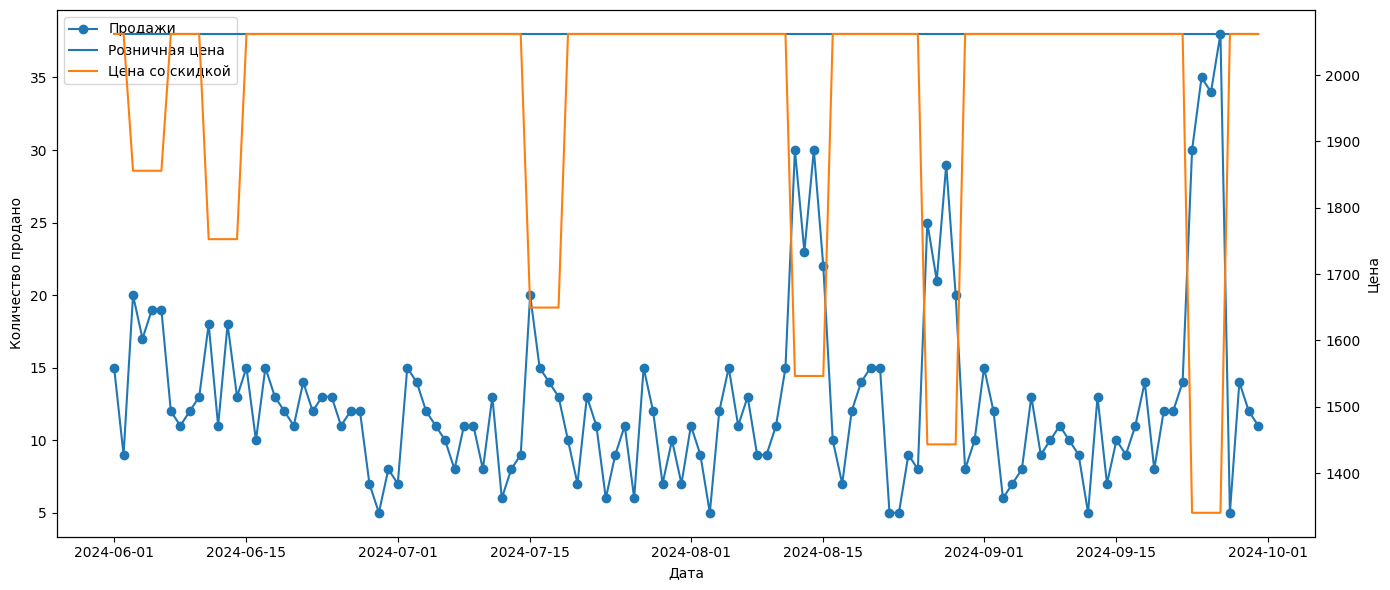

In [35]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Количество продаж
ax1.plot(df_produt["Дата"], df_produt["Количество продано"], marker="o", label="Продажи")
ax1.set_ylabel("Количество продано")

# Цены
ax2 = ax1.twinx()
ax2.plot(df_produt["Дата"], df_produt["Розничная цена"], label="Розничная цена")
ax2.plot(df_produt["Дата"], df_produt["Цена с учётом скидки"], label="Цена со скидкой")

ax2.set_ylabel("Цена")
ax1.set_xlabel("Дата")

# Общая легенда
lines = ax1.get_lines() + ax2.get_lines()
labels = [line.get_label() for line in lines]
ax1.legend(lines, labels, loc="upper left")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### вывод по 3226300004
при обычной цене 271 рублей (исключаем период при цене 289р) без скидки кол-во продаж в среднем 11 упаковок в день. По данным из графика можно сделать вывод, что для повышения проданных упаковок в 2 раза, цену необходимо снижать до приблизительно 203 рублей, что соответствует 25% скидке.  

##### вывод по 15111300017
цена товара без скидки составялет чуть больше 19 тысяч, товар можно отнести к товару высокой ценовой категории. Для среднестатистического покупателя цена является большой, поэтому незначительные скидки на данный товар не повышает спрос на него. И только при цене со скидкой в районе 14.5 тысяч товар становится по карману бОльшему кол-ву покупателей и кол-во проданный упаковок возрастает. Делаем вывод, что данная позиция относится к неэластичному спросу относительно цены и для повышения кол-ва проданный упаковок необходимо применять скидку в 25%, для снижения цены до приблизительно 14.5 тыс. рублей.

##### вывод по 15111300006
спрос на данный товар слабоэластичный, однако более эластичнее чем предидущий. При базовой цене 8057 рублей в среднем продается 9-10 упаковок в день. 10% скидка поднимает спрос в 1.5%. Для повышение спроса в два раза необходимо применить скидку в 20-25%.

##### вывод по 15110900016
спрос на товар более эластичный однако возможна сезонность либо другие факторы из-за чего скидки в июне повышают спрос, в то время как в июле скидка не влияет на спрос. Если необходимо ровысить спрос в два раза не смотря на другие факторы влияния, необходимо будет делать скидку порядка 25% для снижение цены на уровеньь 1100 рублей.

##### вывод по 19760336592
при цене без скидки спрос держится на уровне 10-11 упаковок в день, аналогично прошлому товару наблюдается тенденция повышения спроса при скидке в июне и её отсутвие июле. Возможно погодные условие влияют на спрос (условно крем от загара в пасмурную погоду имеет низкий спрос). Для того что бы реализовать остатки без учета других факторов придется применять скидку в районе 25%.

##### вывод по 14011400047
по данному товару применялись большие скидки от 25 до 40%. Во время всех скидочных компаний наблюдалось повышения спроса, что можно оправдать большими скидками. В среднем без скидки в день продается порядка 9-10 товаров. Для повышения спроса в два раза я бы порекомендовал делать скидку на уровне 25%, на несколько дней, чтобы бОльшая часть людей узнала/успела купить.

##### вывод по 14012900005
данная позиция имеет высокоэластичный спрос под влиянием скидок. Даже 15% скидка повышает спрос в 2 раза, при среднем количестве продаж без скидки приблизительно 8-9 при цене 1223 рублей. При цене 1039 кол-во продаж возрастает до 16-19%.

##### вывод по 19000013047
аналогично прошлой номенклатуре спрос данного товара также является эластичным, проведение всех скидочных акций приводило к повышению спросу. В среднем без проведения акций среднее кол-во проданных упаковок равно 10. Для увеличения проданных товаров в два раза по моему мнению необходимо применить скидку в размере 25%.

##### вывод по 3234800007
базовый спрос на данную позицию при цене без скидки 10-11 упаковок. Спрос на данную позицию является эластичным применение скидки в 25% получается гарантированное удвоение спроса.

##### вывод по 19000000363
в среднем спрос на товар по базовой цене 2062 равен 10-12, спрос на товар является эластичным поэтому даже скидка в 10% повышает спрос и среднее кол-во проданны упаковок на уровне 18-19. Для удвоения базового спроса необходима скидка 20%, что соответсвует цене 1648